In [25]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients

dti_week = [0, 4]
dti = dti[(dti.regionname == 'CST_R') & (dti.Week.isin(dti_week)) & (dti.metric == 'FaMap')] # W0 FA as measure of integrity of affected CST
dti = dti.sort_values('Week').drop_duplicates(['subj_id', 'side'], keep = 'first').reset_index(drop = True) # keep only W0 (or W4 for those wihtout W0)

# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

dti_cerebel = dti.merge(cerebel, on = 'subj_id', suffixes = ('_dti', '_cerebel'))


/localscratch/tmp/ipykernel_34732/2142836548.py:10: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


In [26]:
rows = []
for week in gl.weeks:
    for roi in gl.rois['Nettekoven2024']:
        corr_df = dti_cerebel[(dti_cerebel.Week_cerebel == week) & (dti_cerebel.regionname_bilat == roi)]
        r_stat, p_val = stats.pearsonr(corr_df['asymmetry_index'],corr_df['left_norm'])

        n = len(corr_df.subj_id.unique())
        z, se = np.arctanh(r_stat), 1/np.sqrt(n - 3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows.append({'Week': week, 'roi': roi, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
        
r_df = pd.DataFrame(rows)


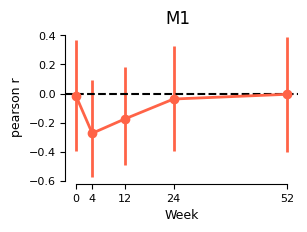

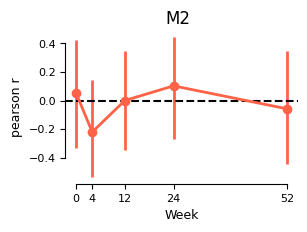

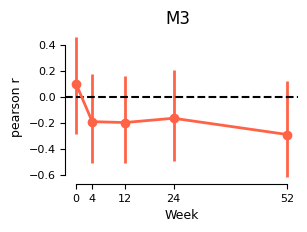

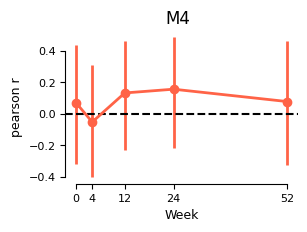

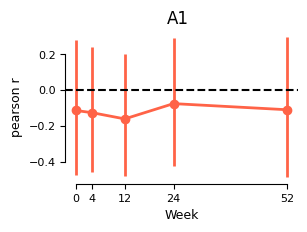

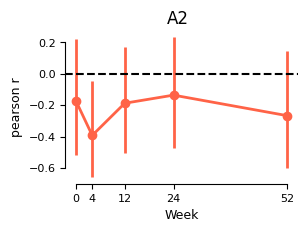

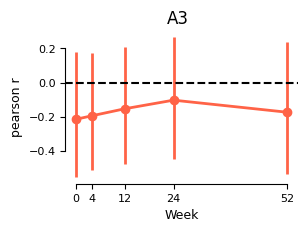

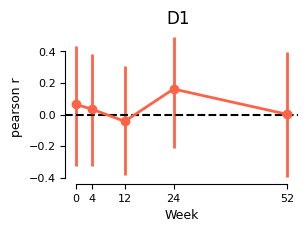

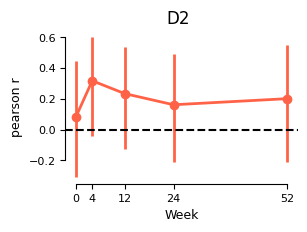

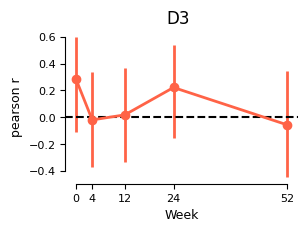

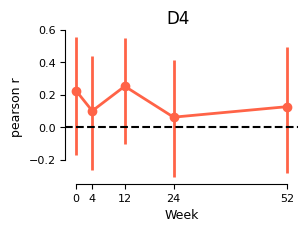

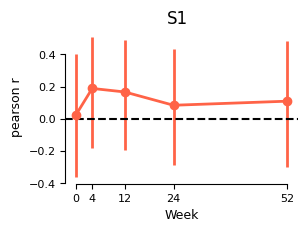

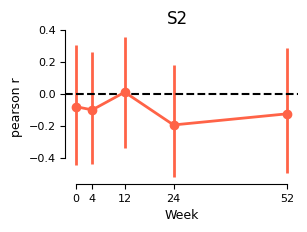

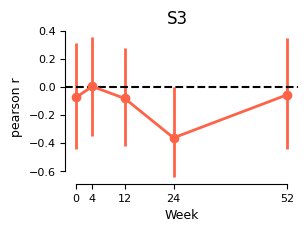

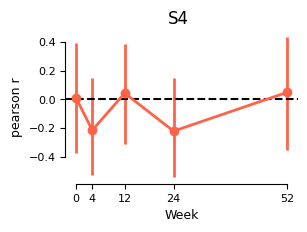

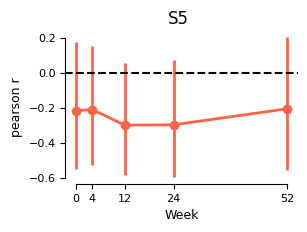

In [27]:
# plot r values for correlations

for roi in gl.rois['Nettekoven2024']:
    plotdf = r_df[r_df['roi'] == roi].sort_values('Week')
    fig, ax = plt.subplots(figsize = (3,2))
    ax.errorbar(x = plotdf['Week'], y = plotdf['r_stat'], yerr = [plotdf['r_stat'] - plotdf['lo'], plotdf['hi'] - plotdf['r_stat']], 
    marker = 'o', linestyle = '-', linewidth = 2, color = 'tomato')

    ax.set_xticks(gl.weeks)
    ax.set_xlabel('Week')
    ax.set_ylabel('pearson r')
    plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
    fig.suptitle(roi)
    sns.despine(trim = True)
    plt.show()

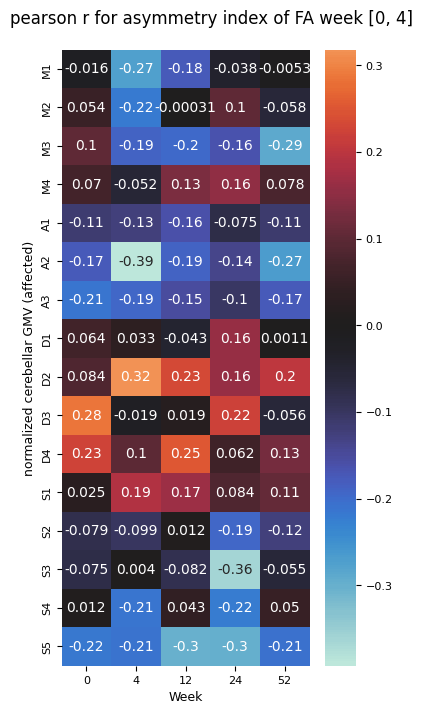

In [28]:
# heatmap
heat = r_df.pivot(index = 'roi', columns = 'Week', values = 'r_stat')
heat = heat.reindex(index = r_df.roi.unique(), columns = r_df.Week.unique())
fig, ax = plt.subplots(figsize = (4,8))
sns.heatmap(heat, center = 0, annot = True, ax = ax)
fig.suptitle(f"pearson r for asymmetry index of FA week {dti_week}", y = .93)
plt.ylabel("normalized cerebellar GMV (affected)")
plt.show()

In [ ]:
# repeat this correlations matrix with behaviour (indiv) rather than cerebellum
# explains residuals of si relationship

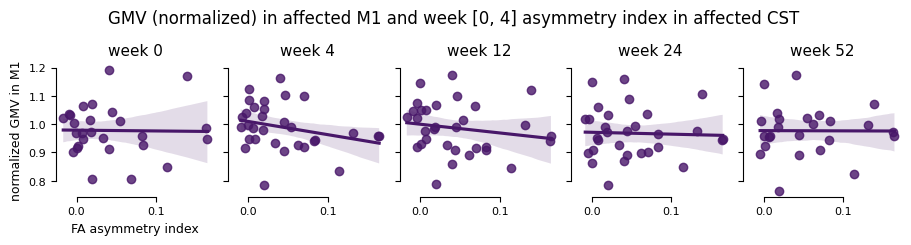

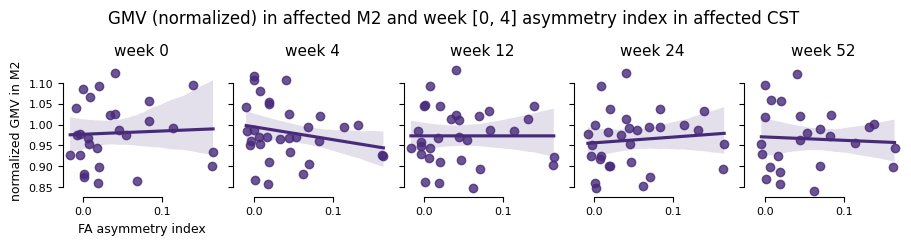

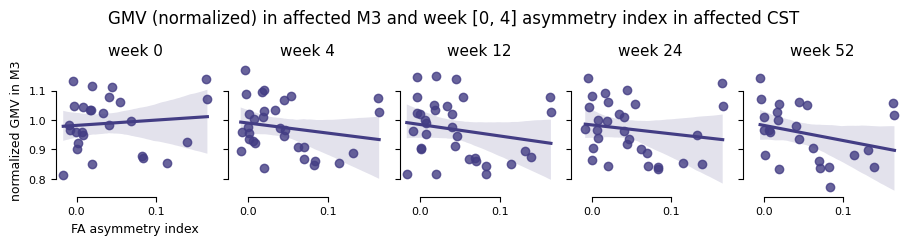

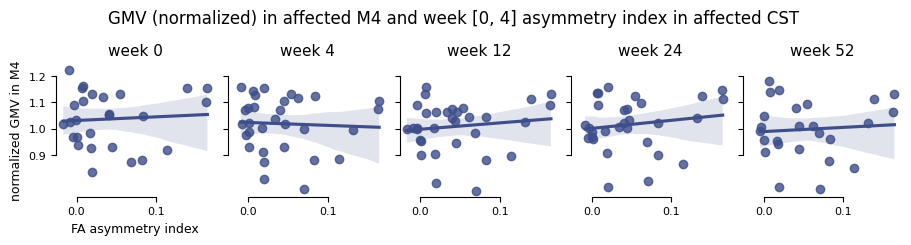

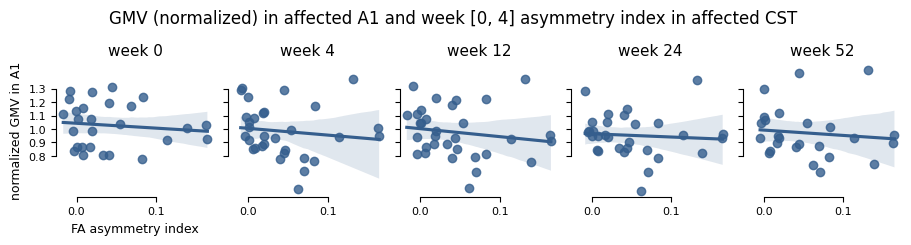

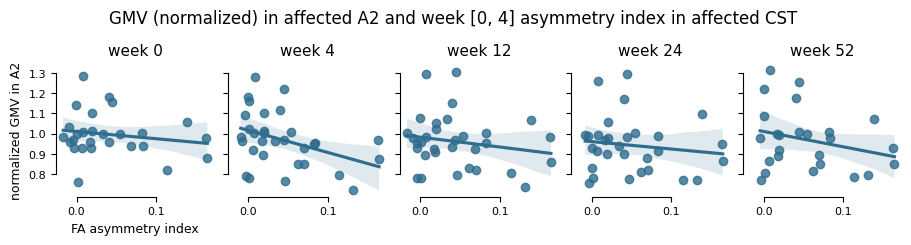

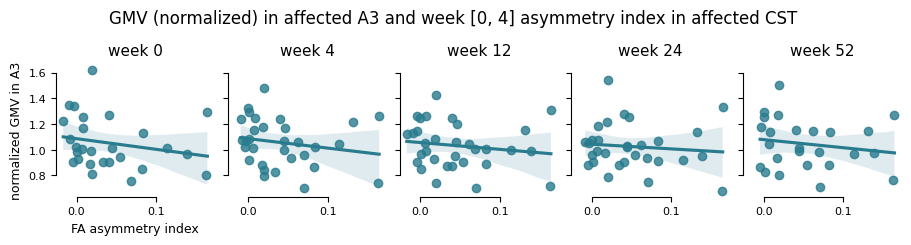

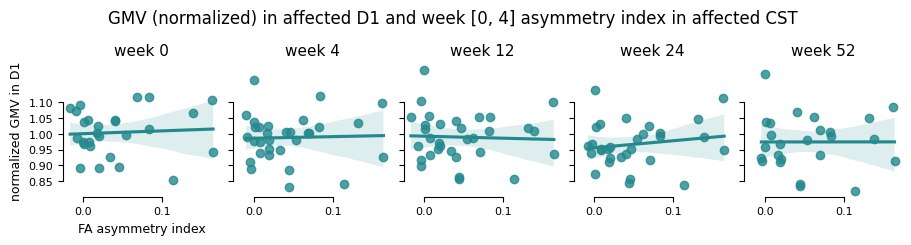

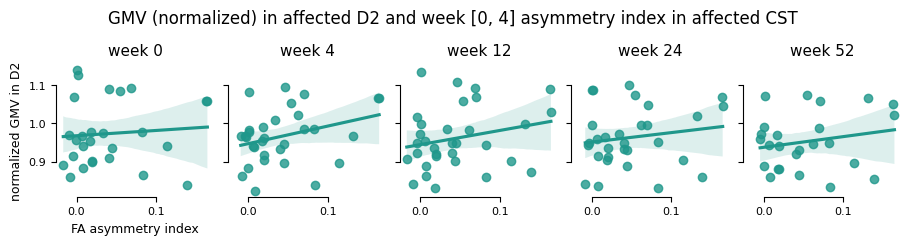

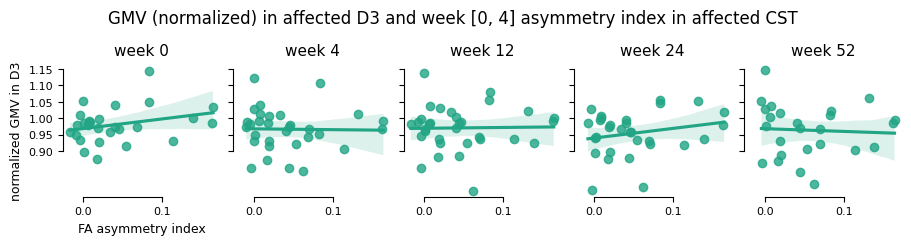

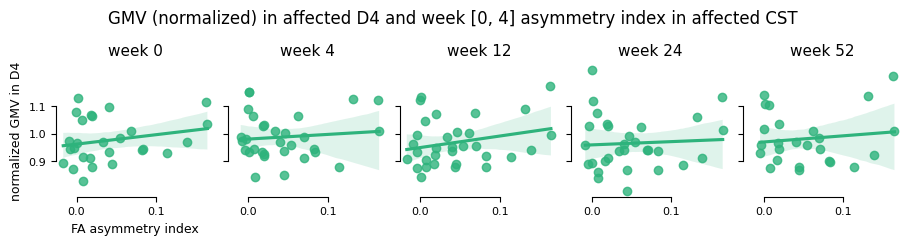

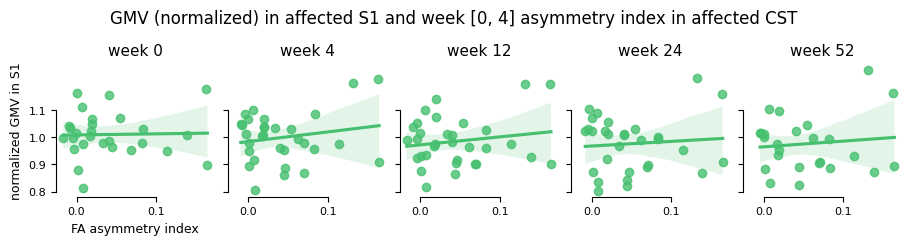

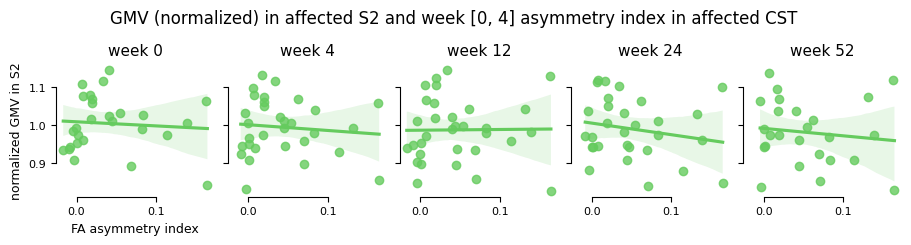

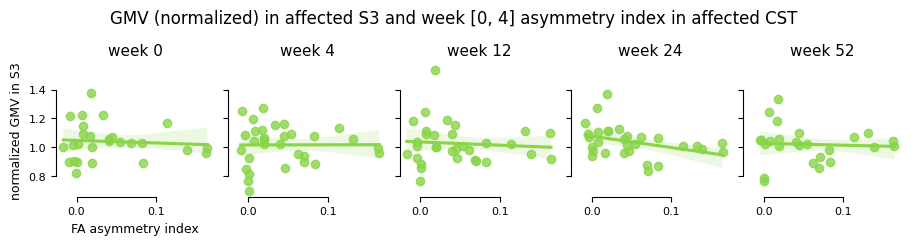

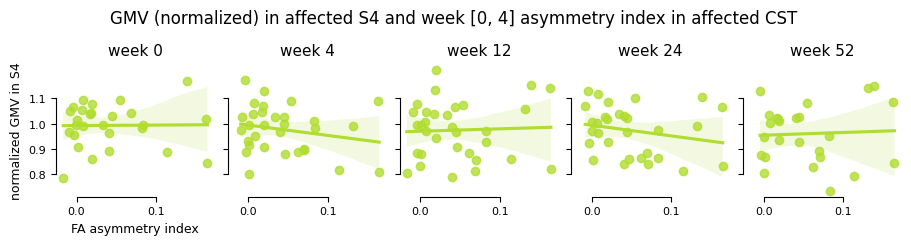

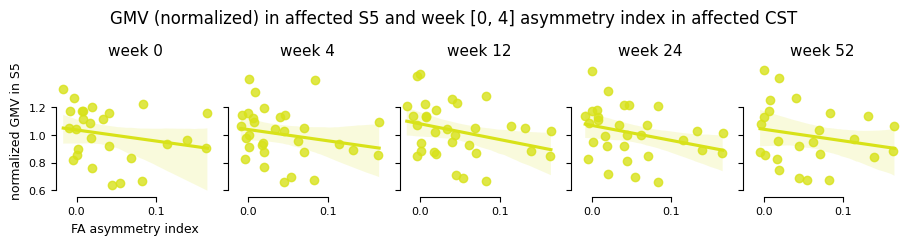

In [29]:
colors = sns.color_palette('viridis', n_colors = len(gl.rois['Nettekoven2024']))

for r, roi in enumerate(gl.rois['Nettekoven2024']):

    fig, axs = plt.subplots(1, 5, figsize = (9,2), sharex = True, sharey = True, constrained_layout = True)
    for i, week in enumerate(gl.weeks):
        ax = axs[i]
        sns.regplot(x = 'asymmetry_index', y = 'left_norm', data = dti_cerebel[(dti_cerebel.regionname_bilat == roi) & (dti_cerebel.Week_cerebel == week)], ax = ax, color = colors[r])
        sns.despine(trim = True)

        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_title(f'week {week}')
        
    axs[0].set_ylabel(f"normalized GMV in {roi}")
    axs[0].set_xlabel(f"FA asymmetry index")
    fig.suptitle(f'GMV (normalized) in affected {roi} and week {dti_week} asymmetry index in affected CST ', y = 1.15)
    plt.show()
